<a href="https://colab.research.google.com/github/Apurva-J509/Linear_Regression/blob/main/Simple_Linear_Regression_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [7]:
students = pd.read_csv('students_dataset.csv')

In [8]:
X = students.loc[:, ['CGPA', 'IQ']]
y = students.loc[:, ['Package_LPA']]

###Linearity in Model

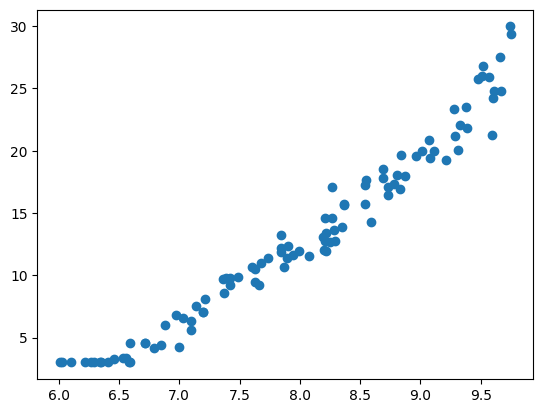

In [23]:
#Checking if there is any linearity in cgpa vs package
plt.scatter(X['CGPA'], y)
plt.show()

###Simple Linear Regression

In [9]:
#Splitting dataset into X_train, X_test, y_train and y_test
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=42)

In [10]:
#Simple Linear Regression class from scratch
class SimpleLinearRegression:
  def __init__(self):
    self.coef_ = None
    self.intercept_ = None

  def fit(self, x_train, y_train):
    den =  np.sum((x_train- x_train.mean())**2)
    self.coef_ = np.sum((x_train-x_train.mean()) * (y_train-y_train.mean()))/den
    self.intercept_ = y_train.mean() - (self.coef_*x_train.mean())

  def predict(self,x_test):
    return self.intercept_ + (self.coef_ * x_test)

In [11]:
#Training model on train dataset
regressor = SimpleLinearRegression()
regressor.fit(X_train['CGPA'], y_train['Package_LPA'])

In [12]:
print('Slope: ', regressor.coef_)
print('Intercept: ', regressor.intercept_)

Slope:  7.017165170287206
Intercept:  -43.0429752386368


In [13]:
#Predicting package of test dataset
y_predicted = regressor.predict(X_test['CGPA'])

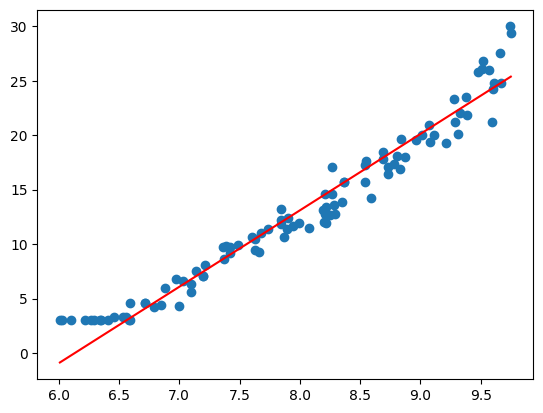

In [14]:
#Best Fit Line
plt.scatter(X['CGPA'], y)
plt.plot(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100), regressor.predict(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100)), color='red')
plt.show()

### Accuracy of Model

In [15]:
#Residual Sum of Squares
def rss(y_predicted, y_test):
  return np.sum((y_predicted - y_test)**2)
#Total Sum of Squares
def tss(y_predicted, y_test):
  return np.sum((y_predicted - y_test.mean())**2)
#Residual Standard Error
def rse(y_predicted, y_test, n):
  df = n - 2
  return np.sqrt(rss(y_predicted, y_test)/df)
#R2 Score
def r2_score(y_predicted, y_test):
  return 1 - (rss(y_predicted, y_test)/tss(y_predicted, y_test))

In [16]:
print("RSE for model: ", rse(y_predicted, y_test['Package_LPA'], 1))
print("R2 Score for model: ", r2_score(y_predicted, y_test['Package_LPA']))

RSE for model:  nan
R2 Score for model:  0.965522086316316


/tmp/ipykernel_5531/2025055523.py:10: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(rss(y_predicted, y_test)/df)


### Accuracy Of Parameters

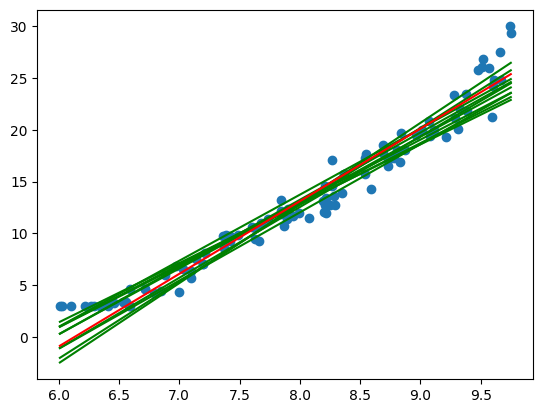

In [17]:
#Comparing population regression line with 10 different sample best fit lines
plt.scatter(X['CGPA'], y)
#Plotting 10 sampels different sample best fit lines
sample_regressor = SimpleLinearRegression()
for i in range(10):
  sample = students.sample(10)
  sample_regressor.fit(sample['CGPA'], sample['Package_LPA'])
  plt.plot(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100), sample_regressor.predict(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100)), color='green')
#Plotting Population Regression Line
plt.plot(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100), regressor.predict(np.linspace(X['CGPA'].min(),X['CGPA'].max(),100)), color='red')
plt.show()

### Standard Error of Parameters

In [18]:
#Standard Error for slope (beta1)
def SE_coef_(x_test, y_predicted, y_test, n):
  return np.sqrt((rse(y_predicted, y_test,n)**2)/ (np.sum((x_test-x_test.mean())**2)))
#Standard Error for intercept (beta0)
def SE_intercept_(x_test, y_predicted, y_test, n):
  return np.sqrt((rse(y_predicted, y_test, n))*((1/n) + ((x_test.mean()**2)/(np.sum((x_test-x_test.mean())**2)))))

In [19]:
print('Standard Error for beta1: ', SE_coef_(X_test['CGPA'], y_predicted, y_test['Package_LPA'], len(y_test)))
print('Standard Error for beta0: ', SE_intercept_(X_test['CGPA'], y_predicted, y_test['Package_LPA'], len(y_test)))

Standard Error for beta1:  0.24628262227145106
Standard Error for beta0:  1.5570729961307743


### Confidence Intervals of Estimated Parameters

In [20]:
#Confidence Interval for slope (beta1)
def CI_coef_(coef_, SE_coef_):
  return (coef_ - (2*SE_coef_), coef_ + (2*SE_coef_))
#Confidence Interval for intercept (beta0)
def CI_intercept_(intercept_, SE_intercept_):
  return (intercept_ - (2*SE_intercept_), intercept_ + (2*SE_intercept_))

In [21]:
CI_coef_(regressor.coef_, SE_coef_(X_test['CGPA'], y_predicted, y_test['Package_LPA'], len(y_test)))
CI_intercept_(regressor.intercept_, SE_intercept_(X_test['CGPA'], y_predicted, y_test['Package_LPA'], len(y_test)))

(np.float64(-46.15712123089835), np.float64(-39.92882924637525))

### p-value for parameters

In [22]:
from scipy.stats import t
def p_value_parameter(parameter, se_parameter, n):
  t_stat = parameter/ se_parameter
  df = n-2
  p_value = 2 * t.sf(abs(t_stat), df)
  return p_value